In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root.
# This works if the notebook is saved inside the project's notebooks/ folder.
PROJECT_ROOT = Path.cwd().parent

# Path to the cleaned BIG KINDS dataset from our previous step.
DATA_FILE = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "bigkinds_news_clean.csv"
)

# Load the data.
df = pd.read_csv(DATA_FILE, encoding="utf-8-sig")

# Convert the date column into datetime format for analysis.
df["News_Date"] = pd.to_datetime(
    df["News_Date"],
    errors="coerce"
)

# Standardize headline whitespace for duplicate checking.
df["Normalized_Headline"] = (
    df["Headline"]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Dataset shape:", df.shape)
print("Date range:", df["News_Date"].min(), "to", df["News_Date"].max())
display(df.head())


Dataset shape: (6414, 7)
Date range: 2026-07-28 00:00:00 to 2026-10-28 00:00:00


,News_ID,News_Date,Publisher,Headline,Is_Financial_News,URL,Normalized_Headline
0,2.100861e+06,2026-07-28,브릿지경제,"김용범 “장특공제 한도, 다주택자 퇴로 등 정책 반영 고민 초고가주택 기준도 조율”",True,https://www.viva100.com/article/20260727500562,"김용범 “장특공제 한도, 다주택자 퇴로 등 정책 반영 고민 초고가주택 기준도 조율”"
1,1.600801e+06,2026-07-28,전남일보,"코스피, 이달 들어 30% 폭락 시총 2천조원 증발",True,https://www.jnilbo.com/news/articleView.html?i...,"코스피, 이달 들어 30% 폭락 시총 2천조원 증발"
2,2.100601e+06,2026-07-28,한국경제,"""대통령은 17.7억 근저당, 국민은 잔금대출 막혀"" 정무위 첫날 난타전",False,https://www.hankyung.com/article/202607280963i,"""대통령은 17.7억 근저당, 국민은 잔금대출 막혀"" 정무위 첫날 난타전"
3,2.100101e+06,2026-07-28,매일경제,SK하이닉스 폭락에 38% 손실 서동주 “전쟁 같은 국장”,True,http://www.mk.co.kr/article/12109526,SK하이닉스 폭락에 38% 손실 서동주 “전쟁 같은 국장”
4,2.100401e+06,2026-07-28,메트로경제,AI 거품 반도체 피크아웃설 CXMT 충격 노이즈가 지배하는 시장,True,http://www.metroseoul.co.kr/article/2026072850...,AI 거품 반도체 피크아웃설 CXMT 충격 노이즈가 지배하는 시장


In [2]:
# Data Quality Checks
# Count articles and dates.
print("Total articles:", len(df))
print("Unique dates:", df["News_Date"].dt.date.nunique())
print("Unique publishers:", df["Publisher"].nunique())

# Check missing values in important columns.
print("\nMissing values:")
display(
    df[["News_ID", "News_Date", "Publisher", "Headline"]]
    .isna()
    .sum()
    .to_frame("Missing_Count")
)

# Check the preliminary financial-news filter.
print("\nFinancial-news flag:")
display(df["Is_Financial_News"].value_counts(dropna=False))

# Check the number of articles per day.
daily_counts = df.groupby(df["News_Date"].dt.date).size()

print("\nArticles per day:")
display(daily_counts.describe().to_frame("Article_Count"))


Total articles: 6414
Unique dates: 93
Unique publishers: 96

Missing values:


,Missing_Count
News_ID,0
News_Date,0
Publisher,0
Headline,0



Financial-news flag:


Is_Financial_News
True     5111
False    1303
Name: count, dtype: int64


Articles per day:


,Article_Count
count,93.000000
mean,68.967742
std,41.093333
min,10.000000
25%,32.000000
50%,70.000000
75%,91.000000
max,187.000000


In [3]:
# Investigate repeated headlines.
# Group articles by normalized headline.
# We keep the source rows for now; this cell only investigates repetition.
headline_counts = (
    df.groupby("Normalized_Headline")
    .agg(
        Article_Count=("News_ID", "size"),
        Publisher_Count=("Publisher", "nunique"),
        First_Date=("News_Date", "min"),
        Last_Date=("News_Date", "max"),
    )
    .sort_values("Article_Count", ascending=False)
)

print(
    "Unique normalized headlines:",
    df["Normalized_Headline"].nunique()
)

print(
    "Headlines appearing more than once:",
    (headline_counts["Article_Count"] > 1).sum()
)

print("\nTop 20 repeated headlines:")
display(headline_counts.head(20))

# Inspect every record associated with the most repeated headline.
if not headline_counts.empty:
    most_repeated = headline_counts.index[0]

    print("\nArticles sharing the most repeated headline:")
    display(
        df.loc[
            df["Normalized_Headline"] == most_repeated,
            ["News_Date", "Publisher", "News_ID", "Headline"]
        ]
    )


Unique normalized headlines: 6212
Headlines appearing more than once: 131

Top 20 repeated headlines:


,Article_Count,Publisher_Count,First_Date,Last_Date
Normalized_Headline,,,,
금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,26,1,2026-08-18,2026-09-03
증시 등락 폭 확대 투자자의 자금 관리 방식도 달라졌다,8,1,2026-09-08,2026-09-17
국제유가 하락에 성장주 부담 완화 증시 반등 탄력받나,7,1,2026-09-28,2026-10-08
연휴 이후 급등락 대비해야 지금 필요한 자금 운용 전략,7,1,2026-09-28,2026-10-08
"투자자금 상품, 금리 기간 상환 방식까지 비교해야 하는 이유",7,1,2026-09-08,2026-09-17
미 10년물 국채 금리 5% 돌파 반도체주 급락,6,1,2026-09-15,2026-09-15
트럼프 “이란 문제 조용히 대응 중” 협상 난항 속 여론도 악화,6,1,2026-08-10,2026-08-10
금시세(금값) 하락,5,1,2026-09-25,2026-10-20
"예보, 서울보증보험 지분 0.6% 매각 공적자금 190억원 회수",4,4,2026-08-19,2026-08-19



Articles sharing the most repeated headline:


,News_Date,Publisher,News_ID,Headline
2126,2026-08-18,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항
2182,2026-08-18,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항
2216,2026-08-19,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항
2306,2026-08-19,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항
2315,2026-08-20,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항
2342,2026-08-20,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항
2388,2026-08-21,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항
2436,2026-08-21,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항
2489,2026-08-24,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항
2520,2026-08-24,이데일리,4.101008e+06,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항


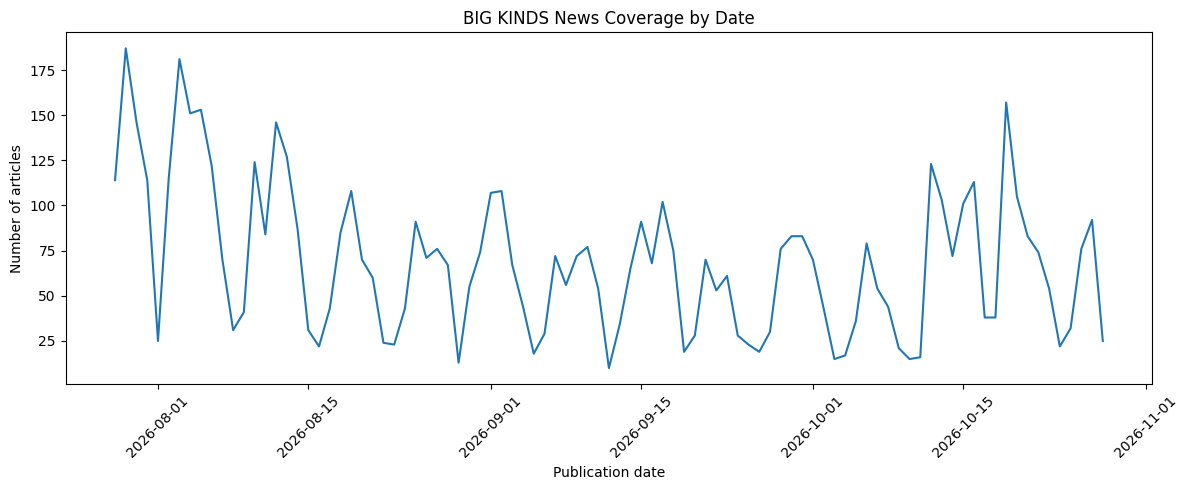

In [4]:
# Visualize article volume over time.
# Count how many articles were published each day.
daily_counts = (
    df.groupby(df["News_Date"].dt.date)
    .size()
)

# Plot article volume over time.
plt.figure(figsize=(12, 5))
daily_counts.plot()
plt.title("BIG KINDS News Coverage by Date")
plt.xlabel("Publication date")
plt.ylabel("Number of articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [5]:

# Diagnose whether repeated headlines represent duplicate records
# or potentially distinct articles.

# IMPORTANT:
# If News_ID was already converted to a number during CSV export,
# this cell cannot restore any lost digits. Reload the original
# BIG KINDS export with dtype=str if the IDs look altered.

# Convert IDs to strings for consistent comparisons.
df["News_ID"] = df["News_ID"].astype("string").str.strip()

# 1. How many IDs are associated with more than one row?
id_counts = df["News_ID"].value_counts(dropna=True)

print("Rows:", len(df))
print("Unique IDs:", df["News_ID"].nunique(dropna=True))
print("IDs appearing more than once:", (id_counts > 1).sum())

print("\nMost repeated IDs:")
display(id_counts.head(15).to_frame("Row_Count"))

# 2. Inspect every row associated with the most repeated headline.
most_repeated_headline = headline_counts.index[0]

print("\nRows for the most repeated headline:")
display(
    df.loc[
        df["Normalized_Headline"] == most_repeated_headline,
        [
            "News_Date",
            "Publisher",
            "News_ID",
            "Headline",
            "URL"
        ]
    ].sort_values("News_Date")
)

# 3. Check whether the same ID has multiple dates or headlines.
id_diagnostics = (
    df[df["News_ID"].notna() & df["News_ID"].ne("")]
    .groupby("News_ID")
    .agg(
        Row_Count=("News_ID", "size"),
        Unique_Dates=("News_Date", "nunique"),
        Unique_Headlines=("Normalized_Headline", "nunique"),
        Unique_Publishers=("Publisher", "nunique"),
    )
    .sort_values("Row_Count", ascending=False)
)

print("\nIDs associated with multiple dates:")
display(id_diagnostics[id_diagnostics["Unique_Dates"] > 1].head(20))

# 4. Count exact duplicate rows across the key article fields.
key_columns = [
    "News_Date",
    "Publisher",
    "News_ID",
    "Normalized_Headline",
    "URL",
]

print(
    "\nExact duplicate rows across key fields:",
    df.duplicated(subset=key_columns, keep="first").sum()
)


Rows: 6414
Unique IDs: 3765
IDs appearing more than once: 1407

Most repeated IDs:


,Row_Count
News_ID,
2100501.202608021,12
2100501.202608191,11
2100701.202610271,10
8100401.202608031,10
4100078.202608031,10
1600451.202610011,9
4100078.202610121,9
2100701.202607291,9
4100078.202607291,9



Rows for the most repeated headline:


,News_Date,Publisher,News_ID,Headline,URL
2126,2026-08-18,이데일리,4101008.202608181,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...
2182,2026-08-18,이데일리,4101008.202608181,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...
2216,2026-08-19,이데일리,4101008.202608191,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...
2306,2026-08-19,이데일리,4101008.202608191,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...
2315,2026-08-20,이데일리,4101008.202608201,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...
2342,2026-08-20,이데일리,4101008.202608201,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...
2388,2026-08-21,이데일리,4101008.202608211,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...
2436,2026-08-21,이데일리,4101008.202608211,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...
2489,2026-08-24,이데일리,4101008.202608241,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...
2520,2026-08-24,이데일리,4101008.202608241,금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,http://www.edaily.co.kr/news/newspath.asp?news...



IDs associated with multiple dates:


,Row_Count,Unique_Dates,Unique_Headlines,Unique_Publishers
News_ID,,,,



Exact duplicate rows across key fields: 0


In [ ]:
# Reload the original export safely
from pathlib import Path
import pandas as pd

RAW_FILE = Path("../data/raw/bigkinds_news.xlsx")

if RAW_FILE.suffix.lower() in [".xlsx", ".xls"]:
    raw = pd.read_excel(RAW_FILE, dtype=str)
elif RAW_FILE.suffix.lower() == ".csv":
    raw = pd.read_csv(RAW_FILE, dtype=str, encoding="utf-8-sig")
elif RAW_FILE.suffix.lower() == ".txt":
    raw = pd.read_csv(
        RAW_FILE,
        sep="\t",
        dtype=str,
        encoding="utf-8-sig"
    )
else:
    raise ValueError(f"Unsupported file type: {RAW_FILE.suffix}")

raw.columns = raw.columns.str.strip()

print("Original rows:", len(raw))
print("Original ID examples:")
print(raw["뉴스 식별자"].head(10).to_list())

print("\nOriginal ID uniqueness:")
print("Unique IDs:", raw["뉴스 식별자"].nunique(dropna=True))
print("Missing IDs:", raw["뉴스 식별자"].isna().sum())

c:\Users\og\Documents\Thesis\vscode\.venv\lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Original rows: 6414
Original ID examples:
['01600451.20261028094831001', '02100311.20261028093914001', '02100311.20261028092203001', '02100851.20261028085316001', '02100351.20261028084116001', '02100351.20261028083548001', '02100701.20261028083235001', '04100078.20261028082802001', '04101008.20261028082136002', '02100101.20261028080322001']

Original ID uniqueness:
Unique IDs: 6414
Missing IDs: 0


In [ ]:
# Compare records sharing an ID
raw["뉴스 식별자"] = raw["뉴스 식별자"].fillna("").astype(str).str.strip()
raw["일자"] = raw["일자"].fillna("").astype(str).str.strip()
raw["제목"] = raw["제목"].fillna("").astype(str).str.strip()
raw["언론사"] = raw["언론사"].fillna("").astype(str).str.strip()
raw["URL"] = raw["URL"].fillna("").astype(str).str.strip()

id_summary = (
    raw[raw["뉴스 식별자"] != ""]
    .groupby("뉴스 식별자")
    .agg(
        Row_Count=("뉴스 식별자", "size"),
        Unique_Dates=("일자", "nunique"),
        Unique_Headlines=("제목", "nunique"),
        Unique_Publishers=("언론사", "nunique"),
        Unique_URLs=("URL", "nunique"),
    )
    .sort_values("Row_Count", ascending=False)
)

display(id_summary.head(15))

# Inspect one of the most repeated IDs
sample_id = id_summary.index[0]

display(
    raw.loc[
        raw["뉴스 식별자"] == sample_id,
        ["뉴스 식별자", "일자", "언론사", "제목", "URL", "본문"]
    ].head(20)
)

,Row_Count,Unique_Dates,Unique_Headlines,Unique_Publishers,Unique_URLs
뉴스 식별자,,,,,
10100401.20261012142756001,1,1,1,1,1
01100101.20260728204659001,1,1,1,1,1
01100101.20260729112559001,1,1,1,1,1
01100101.20260729144834001,1,1,1,1,1
01100101.20260729214722003,1,1,1,1,1
01100101.20260729221539001,1,1,1,1,1
01100101.20260730113545001,1,1,1,1,1
01100101.20260730203101001,1,1,1,1,1
01100101.20260730213139001,1,1,1,1,1


,뉴스 식별자,일자,언론사,제목,URL,본문
1234,10100401.20261012142756001,20261012,스포츠월드,"[이문원의 쇼비즈워치] 위험한 베팅, 매력적인 서사",http://www.sportsworldi.com/content/html/2026/...,10월 영화시장 화젯거리는 크게 둘이다. 먼저 역사 왜곡 논란으로 불붙은 정치 사회...


In [10]:
# Rebuild the cleaned dataset from the original BIG KINDS export.
# Keep article IDs as strings throughout.

clean_df = pd.DataFrame({
    "News_ID": raw["뉴스 식별자"].astype("string").str.strip(),
    "News_Date": pd.to_datetime(
        raw["일자"].astype("string").str.strip(),
        format="%Y%m%d",
        errors="coerce"
    ),
    "Publisher": raw["언론사"].astype("string").str.strip(),
    "Headline": raw["제목"].astype("string").str.strip(),
    "URL": raw["URL"].astype("string").str.strip(),
    "Body": raw["본문"].astype("string").str.strip(),
    "Category_1": raw["통합 분류1"].astype("string").str.strip(),
    "Category_2": raw["통합 분류2"].astype("string").str.strip(),
    "Category_3": raw["통합 분류3"].astype("string").str.strip(),
})

# Remove rows without a usable date or headline.
clean_df = clean_df.dropna(subset=["News_Date"])
clean_df = clean_df[
    clean_df["Headline"].notna()
    & clean_df["Headline"].ne("")
].copy()

# Normalize headlines for duplicate investigation.
clean_df["Normalized_Headline"] = (
    clean_df["Headline"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Cleaned rows:", len(clean_df))
print("Unique article IDs:", clean_df["News_ID"].nunique())
print("Missing IDs:", clean_df["News_ID"].isna().sum())
print(
    "Duplicate IDs:",
    clean_df["News_ID"].duplicated().sum()
)

display(clean_df.head())

Cleaned rows: 6414
Unique article IDs: 6414
Missing IDs: 0
Duplicate IDs: 0


,News_ID,News_Date,Publisher,Headline,URL,Body,Category_1,Category_2,Category_3,Normalized_Headline
0,01600451.20261028094831001,2026-10-28,남도일보,"[특징주] 한미약품, 283억 원 규모 자사주 소각 결정에 6%대 강세",https://www.namdonews.com/news/articleView.htm...,한미약품이 약 283억 원 규모의 자사주 소각을 결정했다는 소식에 장 초반 6%대 ...,경제>증권_증시,경제>부동산,경제>금융_재테크,"[특징주] 한미약품, 283억 원 규모 자사주 소각 결정에 6%대 강세"
1,02100311.20261028093914001,2026-10-28,서울경제,115년 만에 시장 옮긴다고 GM이 테크주 되나 [트럼프 스톡커],https://www.sedaily.com/article/20106996?ref=kpf,"■윤경환 특파원의 트럼프 스톡커(Stocker) <347>\nGM, NYSE 상장 ...",경제>자동차,경제>증권_증시,경제>반도체,115년 만에 시장 옮긴다고 GM이 테크주 되나 [트럼프 스톡커]
2,02100311.20261028092203001,2026-10-28,서울경제,"SK하이닉스, 지금 사도 2만원 배당받는다",https://www.sedaily.com/article/20106968?ref=kpf,배당기준일 11월 30일로 정해져\n신규 투자자에도 배당 기회 열려\n\n\nSK하...,경제>국제경제,경제>금융_재테크,경제>증권_증시,"SK하이닉스, 지금 사도 2만원 배당받는다"
3,02100851.20261028085316001,2026-10-28,아주경제,"[인문자의 2027년 투자와 인생 이야기 | 인간 문화 자연] 2027년, 돈은 어...",https://www.ajunews.com/view/20261028083254919,해마다 가을이 깊어지면 서점에는 다음 해를 전망하는 책들이 쏟아진다. 경제학자는 성...,경제>경제일반,<NA>,<NA>,"[인문자의 2027년 투자와 인생 이야기 | 인간 문화 자연] 2027년, 돈은 어..."
4,02100351.20261028084116001,2026-10-28,이투데이,"KB운용, 스페이스X 테슬라 동시 투자 ETF 주목 우주 로봇 성장성 겨냥",https://www.etoday.co.kr/news/view/2640895,[이투데이] 유한새 기자 (bird@etoday.co.kr)\n\n\n\n우주산업과...,IT_과학>과학,경제>증권_증시,경제>무역,"KB운용, 스페이스X 테슬라 동시 투자 ETF 주목 우주 로봇 성장성 겨냥"


In [11]:
# Investigate repeated headlines correctly
headline_counts = (
    clean_df.groupby("Normalized_Headline")
    .agg(
        Row_Count=("News_ID", "size"),
        Unique_IDs=("News_ID", "nunique"),
        Unique_Dates=("News_Date", "nunique"),
        Unique_Publishers=("Publisher", "nunique"),
        Unique_URLs=("URL", "nunique"),
    )
    .query("Row_Count > 1")
    .sort_values("Row_Count", ascending=False)
)

print("Repeated headline groups:", len(headline_counts))
display(headline_counts.head(15))

Repeated headline groups: 131


,Row_Count,Unique_IDs,Unique_Dates,Unique_Publishers,Unique_URLs
Normalized_Headline,,,,,
금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,26,26,13,1,26
증시 등락 폭 확대 투자자의 자금 관리 방식도 달라졌다,8,8,8,1,8
연휴 이후 급등락 대비해야 지금 필요한 자금 운용 전략,7,7,7,1,7
"투자자금 상품, 금리 기간 상환 방식까지 비교해야 하는 이유",7,7,7,1,7
국제유가 하락에 성장주 부담 완화 증시 반등 탄력받나,7,7,7,1,7
트럼프 “이란 문제 조용히 대응 중” 협상 난항 속 여론도 악화,6,6,1,1,6
미 10년물 국채 금리 5% 돌파 반도체주 급락,6,6,1,1,6
금시세(금값) 하락,5,5,5,1,5
오늘부터 퇴근 후 8시까지 주식 매매 한국거래소 애프터마켓 개장,4,4,1,1,4


In [12]:
# Save the corrected dataset
from pathlib import Path

OUTPUT_FILE = Path("data/processed/bigkinds_news_clean_v2.csv")
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

clean_df.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", OUTPUT_FILE.resolve())

Saved: C:\Users\og\Documents\Thesis\vscode\notebooks\data\processed\bigkinds_news_clean_v2.csv


In [13]:
#Count all BIG KINDS categories
# Combine all three classification columns
category_columns = ["Category_1", "Category_2", "Category_3"]

category_data = clean_df[category_columns].melt(
    value_name="Category"
)

category_data["Category"] = (
    category_data["Category"]
    .astype("string")
    .str.strip()
)

category_data = category_data[
    category_data["Category"].notna()
    & category_data["Category"].ne("")
    & category_data["Category"].ne("<NA>")
]

category_counts = (
    category_data["Category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Article_Count")
)

category_counts["Percentage"] = (
    category_counts["Article_Count"] / len(clean_df) * 100
).round(2)

display(category_counts.head(30))

,Category,Article_Count,Percentage
0,경제>증권_증시,4299,67.03
1,경제>금융_재테크,2007,31.29
2,경제>외환,1805,28.14
3,경제>유통,1448,22.58
4,경제>국제경제,1349,21.03
5,경제>반도체,1106,17.24
6,정치>청와대,968,15.09
7,정치>국회_정당,749,11.68
8,경제>부동산,675,10.52
9,경제>무역,367,5.72


In [ ]:
# Inspect potentially relevant categories
economic_categories = category_counts[
    category_counts["Category"].str.startswith("경제>", na=False)
].copy()

display(economic_categories)

,Category,Article_Count,Percentage
0,경제>증권_증시,4299,67.03
1,경제>금융_재테크,2007,31.29
2,경제>외환,1805,28.14
3,경제>유통,1448,22.58
4,경제>국제경제,1349,21.03
5,경제>반도체,1106,17.24
8,경제>부동산,675,10.52
9,경제>무역,367,5.72
12,경제>산업_기업,300,4.68
13,경제>자동차,293,4.57


In [15]:
# Financial News Subset Selection
# Define the subsets
# Narrow: directly related to financial markets and investment
narrow_categories = {
    "경제>증권_증시",
    "경제>금융_재테크",
}

# Broad: narrow categories plus other potentially market-relevant topics
broad_categories = narrow_categories | {
    "경제>외환",
    "경제>국제경제",
    "경제>반도체",
    "경제>무역",
    "경제>산업_기업",
    "경제>경제일반",
    "경제>자원",
    "경제>자동차",
}

# Check whether an article has at least one selected category
def has_category(row, selected_categories):
    article_categories = set(
        row[category_columns].dropna().astype(str).str.strip()
    )
    return bool(article_categories & selected_categories)

clean_df["Narrow_Financial"] = clean_df.apply(
    lambda row: has_category(row, narrow_categories),
    axis=1
)

clean_df["Broad_Economic"] = clean_df.apply(
    lambda row: has_category(row, broad_categories),
    axis=1
)

narrow_df = clean_df[clean_df["Narrow_Financial"]].copy()
broad_df = clean_df[clean_df["Broad_Economic"]].copy()

print("Total articles:", len(clean_df))
print("Narrow financial articles:", len(narrow_df))
print("Broad economic articles:", len(broad_df))
print(
    "Additional articles in broad subset:",
    len(broad_df) - len(narrow_df)
)

Total articles: 6414
Narrow financial articles: 4680
Broad economic articles: 5356
Additional articles in broad subset: 676


In [16]:
# compare the results
comparison = pd.DataFrame({
    "Dataset": ["Narrow Financial", "Broad Economic"],
    "Article_Count": [len(narrow_df), len(broad_df)],
    "Unique_Dates": [
        narrow_df["News_Date"].nunique(),
        broad_df["News_Date"].nunique()
    ],
    "Unique_Publishers": [
        narrow_df["Publisher"].nunique(),
        broad_df["Publisher"].nunique()
    ],
    "Percentage_of_Total": [
        round(len(narrow_df) / len(clean_df) * 100, 2),
        round(len(broad_df) / len(clean_df) * 100, 2)
    ]
})

display(comparison)

,Dataset,Article_Count,Unique_Dates,Unique_Publishers,Percentage_of_Total
0,Narrow Financial,4680,93,87,72.97
1,Broad Economic,5356,93,90,83.50


In [17]:
# save both subsets
from pathlib import Path

OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

narrow_df.to_csv(
    OUTPUT_DIR / "bigkinds_narrow_financial.csv",
    index=False,
    encoding="utf-8-sig"
)

broad_df.to_csv(
    OUTPUT_DIR / "bigkinds_broad_economic.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Both datasets saved successfully.")

Both datasets saved successfully.


In [18]:
# Text Quality and Daily Coverage
# Check missing and short text
text_quality = pd.DataFrame({
    "Dataset": ["Narrow Financial", "Broad Economic"],
    "Total_Articles": [len(narrow_df), len(broad_df)],
    "Missing_Headlines": [
        narrow_df["Headline"].isna().sum(),
        broad_df["Headline"].isna().sum()
    ],
    "Missing_Bodies": [
        narrow_df["Body"].isna().sum(),
        broad_df["Body"].isna().sum()
    ],
    "Empty_Bodies": [
        narrow_df["Body"].fillna("").str.strip().eq("").sum(),
        broad_df["Body"].fillna("").str.strip().eq("").sum()
    ],
    "Unique_Headlines": [
        narrow_df["Normalized_Headline"].nunique(),
        broad_df["Normalized_Headline"].nunique()
    ]
})

display(text_quality)

,Dataset,Total_Articles,Missing_Headlines,Missing_Bodies,Empty_Bodies,Unique_Headlines
0,Narrow Financial,4680,0,0,0,4522
1,Broad Economic,5356,0,0,0,5183


,Narrow,Broad
count,93.00,93.00
mean,50.32,57.59
std,28.91,32.71
min,7.00,9.00
25%,24.00,28.00
50%,52.00,56.00
75%,68.00,79.00
max,158.00,166.00


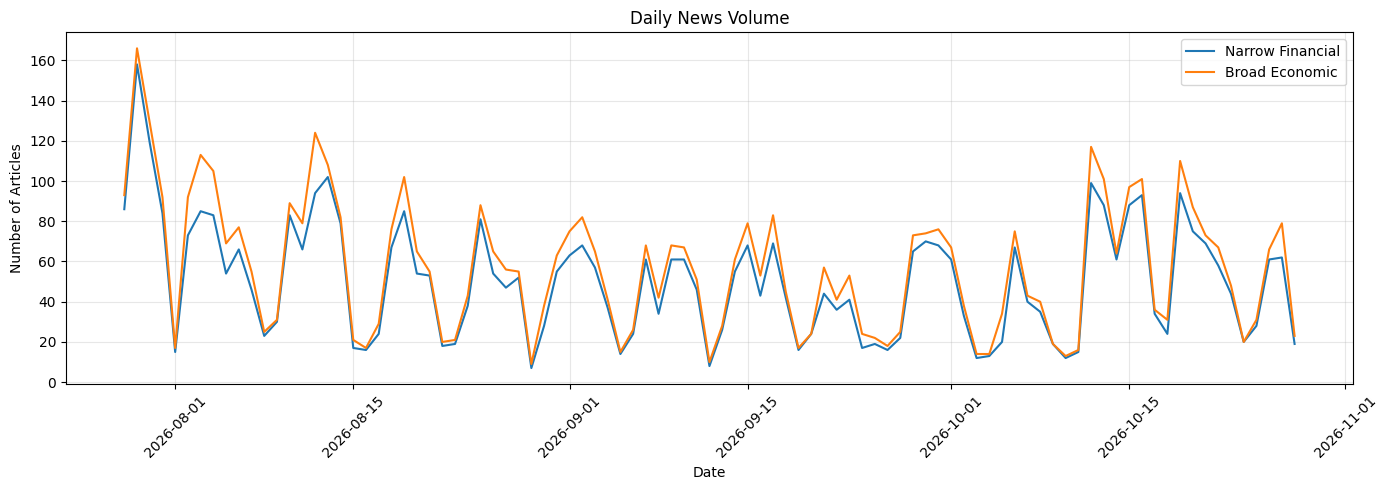

In [19]:
# Check article volume by date
daily_counts = pd.DataFrame({
    "Narrow": narrow_df.groupby("News_Date").size(),
    "Broad": broad_df.groupby("News_Date").size()
}).fillna(0)

daily_counts.index = pd.to_datetime(daily_counts.index)

display(daily_counts.describe().round(2))

plt.figure(figsize=(14, 5))
plt.plot(daily_counts.index, daily_counts["Narrow"], label="Narrow Financial")
plt.plot(daily_counts.index, daily_counts["Broad"], label="Broad Economic")

plt.title("Daily News Volume")
plt.xlabel("Date")
plt.ylabel("Number of Articles")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Check whether the two datasets cover the same dates
coverage = pd.DataFrame({
    "Narrow_Articles": narrow_df.groupby("News_Date").size(),
    "Broad_Articles": broad_df.groupby("News_Date").size()
}).fillna(0)

coverage["Narrow_Articles"] = coverage["Narrow_Articles"].astype(int)
coverage["Broad_Articles"] = coverage["Broad_Articles"].astype(int)

coverage["Narrow_Coverage"] = coverage["Narrow_Articles"] > 0
coverage["Broad_Coverage"] = coverage["Broad_Articles"] > 0

print("Dates covered by narrow:", coverage["Narrow_Coverage"].sum())
print("Dates covered by broad:", coverage["Broad_Coverage"].sum())
print("Dates with no narrow articles:", (~coverage["Narrow_Coverage"]).sum())
print("Dates with no broad articles:", (~coverage["Broad_Coverage"]).sum())

Dates covered by narrow: 93
Dates covered by broad: 93
Dates with no narrow articles: 0
Dates with no broad articles: 0


In [21]:
# Korean Financial News Sentiment Analysis
# Load the model and inspect its labels
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

MODEL_NAME = "snunlp/KR-FinBERT-SC"

device = 0 if torch.cuda.is_available() else -1

print("Device:", "GPU" if device == 0 else "CPU")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)

print("\nModel labels:")
print(model.config.id2label)

print("\nNumber of classes:", model.config.num_labels)

c:\Users\og\Documents\Thesis\vscode\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: CPU

Model labels:
{0: 'negative', 1: 'neutral', 2: 'positive'}

Number of classes: 3


In [22]:
# Run a small test
sentiment_model = pipeline(
    "text-classification",
    model=model,
    tokenizer=tokenizer,
    device=device
)

test_headlines = broad_df["Headline"].head(5).tolist()

test_results = sentiment_model(
    test_headlines,
    truncation=True,
    max_length=128,
    top_k=None
)

for headline, result in zip(test_headlines, test_results):
    print("\nHeadline:", headline)
    print("Scores:", result)

Device set to use cpu



Headline: [특징주] 한미약품, 283억 원 규모 자사주 소각 결정에 6%대 강세
Scores: [{'label': 'positive', 'score': 0.9998807907104492}, {'label': 'neutral', 'score': 7.81585622462444e-05}, {'label': 'negative', 'score': 4.100102523807436e-05}]

Headline: 115년 만에 시장 옮긴다고 GM이 테크주 되나 [트럼프 스톡커]
Scores: [{'label': 'neutral', 'score': 0.5552542805671692}, {'label': 'positive', 'score': 0.3969263434410095}, {'label': 'negative', 'score': 0.04781939089298248}]

Headline: SK하이닉스, 지금 사도 2만원 배당받는다
Scores: [{'label': 'positive', 'score': 0.9998682737350464}, {'label': 'neutral', 'score': 8.949555194703862e-05}, {'label': 'negative', 'score': 4.222224742989056e-05}]

Headline: [인문자의 2027년 투자와 인생 이야기 | 인간 문화 자연] 2027년, 돈은 어디로 가고 인간은 어디로 가는가 -『머니 트렌드 2027』과 『트렌드 코리아 2027』으로 읽는 AI 대전환 시대의 투자와 인생
Scores: [{'label': 'neutral', 'score': 0.9999135732650757}, {'label': 'positive', 'score': 4.7465928219025955e-05}, {'label': 'negative', 'score': 3.8990085158729926e-05}]

Headline: KB운용, 스페이스X 테슬라 동시 투자 ETF 주목 우주 로봇 성장성 겨냥
Scores: 

In [23]:
# Score all 5,356 articles
import numpy as np
from tqdm.auto import tqdm

headlines = broad_df["Headline"].fillna("").astype(str).tolist()

batch_size = 32
all_predictions = []

for start in tqdm(range(0, len(headlines), batch_size)):
    batch = headlines[start:start + batch_size]

    predictions = sentiment_model(
        batch,
        truncation=True,
        max_length=128,
        top_k=None
    )

    all_predictions.extend(predictions)

print("Articles processed:", len(all_predictions))

100%|██████████| 168/168 [03:28<00:00,  1.24s/it]

Articles processed: 5356


In [24]:
# Convert predictions into a dataframe
sentiment_rows = []

for news_id, headline, prediction in zip(
    broad_df["News_ID"],
    headlines,
    all_predictions
):
    row = {
        "News_ID": news_id,
        "Headline": headline
    }

    for item in prediction:
        row[item["label"]] = item["score"]

    sentiment_rows.append(row)

sentiment_df = pd.DataFrame(sentiment_rows)

display(sentiment_df.head())

,News_ID,Headline,positive,neutral,negative
0,01600451.20261028094831001,"[특징주] 한미약품, 283억 원 규모 자사주 소각 결정에 6%대 강세",0.999881,0.000078,0.000041
1,02100311.20261028093914001,115년 만에 시장 옮긴다고 GM이 테크주 되나 [트럼프 스톡커],0.396926,0.555254,0.047819
2,02100311.20261028092203001,"SK하이닉스, 지금 사도 2만원 배당받는다",0.999868,0.000089,0.000042
3,02100851.20261028085316001,"[인문자의 2027년 투자와 인생 이야기 | 인간 문화 자연] 2027년, 돈은 어...",0.000047,0.999914,0.000039
4,02100351.20261028084116001,"KB운용, 스페이스X 테슬라 동시 투자 ETF 주목 우주 로봇 성장성 겨냥",0.000170,0.999802,0.000028


In [25]:
# Verify all articles were processed
print("Expected articles:", len(broad_df))
print("Predictions generated:", len(all_predictions))
print("Sentiment rows:", len(sentiment_df))

assert len(all_predictions) == len(broad_df)
assert len(sentiment_df) == len(broad_df)

print("All articles successfully scored.")

Expected articles: 5356
Predictions generated: 5356
Sentiment rows: 5356
All articles successfully scored.


In [26]:
# Attach dates and dataset membership

In [27]:
# Attach publication dates and narrow/broad membership
article_sentiment = broad_df[
    ["News_ID", "News_Date", "Narrow_Financial"]
].merge(
    sentiment_df,
    on="News_ID",
    how="inner",
    validate="one_to_one"
)

print("Matched articles:", len(article_sentiment))
display(article_sentiment.head())

Matched articles: 5356


,News_ID,News_Date,Narrow_Financial,Headline,positive,neutral,negative
0,01600451.20261028094831001,2026-10-28,True,"[특징주] 한미약품, 283억 원 규모 자사주 소각 결정에 6%대 강세",0.999881,0.000078,0.000041
1,02100311.20261028093914001,2026-10-28,True,115년 만에 시장 옮긴다고 GM이 테크주 되나 [트럼프 스톡커],0.396926,0.555254,0.047819
2,02100311.20261028092203001,2026-10-28,True,"SK하이닉스, 지금 사도 2만원 배당받는다",0.999868,0.000089,0.000042
3,02100851.20261028085316001,2026-10-28,False,"[인문자의 2027년 투자와 인생 이야기 | 인간 문화 자연] 2027년, 돈은 어...",0.000047,0.999914,0.000039
4,02100351.20261028084116001,2026-10-28,True,"KB운용, 스페이스X 테슬라 동시 투자 ETF 주목 우주 로봇 성장성 겨냥",0.000170,0.999802,0.000028


In [28]:
# Aggregate sentiment by publication date

In [29]:
# Aggregate sentiment by publication date
def aggregate_daily_sentiment(data):
    data = data.copy()

    # Predicted sentiment class
    data["Predicted_Class"] = (
        data[["positive", "neutral", "negative"]]
        .idxmax(axis=1)
    )

    daily = data.groupby("News_Date").agg(
        Article_Count=("News_ID", "count"),
        Mean_Positive=("positive", "mean"),
        Mean_Neutral=("neutral", "mean"),
        Mean_Negative=("negative", "mean"),
    )

    # Proportion of articles assigned to each class
    proportions = pd.crosstab(
        data["News_Date"],
        data["Predicted_Class"],
        normalize="index"
    )

    proportions = proportions.rename(columns={
        "positive": "Positive_Proportion",
        "neutral": "Neutral_Proportion",
        "negative": "Negative_Proportion"
    })

    daily = daily.join(proportions, how="left")

    # Net sentiment based on model probabilities
    daily["Sentiment_Score"] = (
        daily["Mean_Positive"] - daily["Mean_Negative"]
    )

    return daily.fillna(0).sort_index()


# Broad economic sentiment
broad_daily = aggregate_daily_sentiment(article_sentiment)

# Narrow financial sentiment
narrow_daily = aggregate_daily_sentiment(
    article_sentiment[
        article_sentiment["Narrow_Financial"]
    ]
)

print("Broad daily observations:", len(broad_daily))
print("Narrow daily observations:", len(narrow_daily))

display(broad_daily.head())
display(narrow_daily.head())

Broad daily observations: 93
Narrow daily observations: 93


,Article_Count,Mean_Positive,Mean_Neutral,Mean_Negative,Negative_Proportion,Neutral_Proportion,Positive_Proportion,Sentiment_Score
News_Date,,,,,,,,
2026-07-28,93,0.081898,0.640312,0.277790,0.290323,0.634409,0.075269,-0.195892
2026-07-29,166,0.088694,0.626387,0.284920,0.277108,0.638554,0.084337,-0.196226
2026-07-30,129,0.082745,0.746690,0.170566,0.155039,0.759690,0.085271,-0.087821
2026-07-31,92,0.147534,0.672332,0.180135,0.184783,0.673913,0.141304,-0.032601
2026-08-01,17,0.060695,0.767202,0.172103,0.176471,0.764706,0.058824,-0.111408


,Article_Count,Mean_Positive,Mean_Neutral,Mean_Negative,Negative_Proportion,Neutral_Proportion,Positive_Proportion,Sentiment_Score
News_Date,,,,,,,,
2026-07-28,86,0.076304,0.635014,0.288682,0.302326,0.627907,0.069767,-0.212378
2026-07-29,158,0.081169,0.619950,0.298880,0.291139,0.632911,0.075949,-0.217711
2026-07-30,119,0.089521,0.742182,0.168297,0.151261,0.756303,0.092437,-0.078776
2026-07-31,84,0.161276,0.665223,0.173501,0.178571,0.666667,0.154762,-0.012224
2026-08-01,15,0.068436,0.768525,0.163039,0.200000,0.733333,0.066667,-0.094604


In [30]:
# Visualize daily sentiment

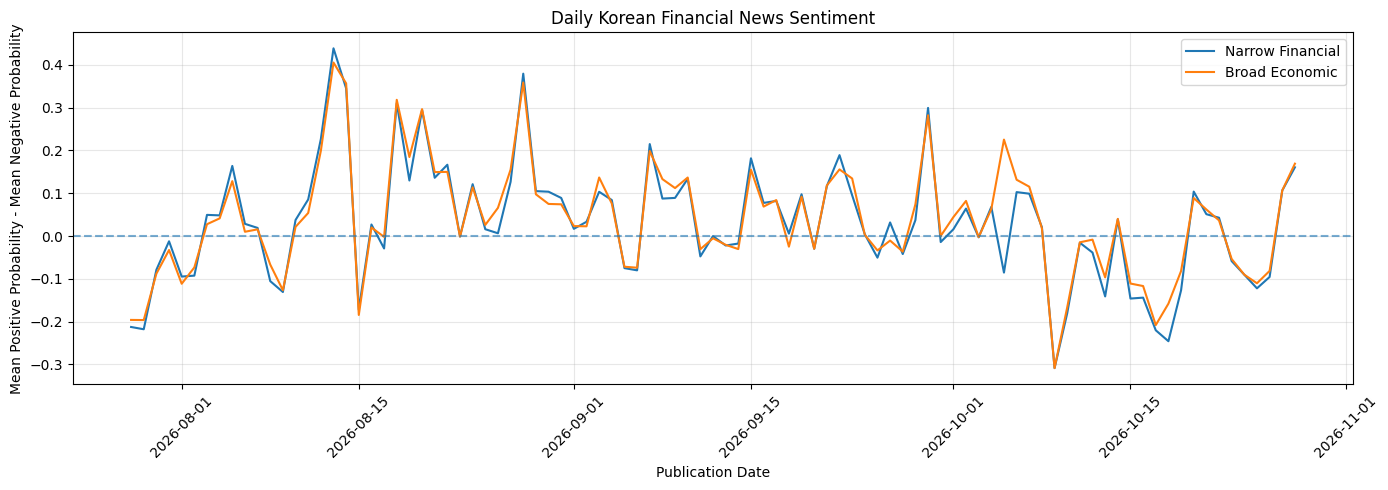

In [31]:
# Visualize daily sentiment
plt.figure(figsize=(14, 5))

plt.plot(
    narrow_daily.index,
    narrow_daily["Sentiment_Score"],
    label="Narrow Financial",
    linewidth=1.5
)

plt.plot(
    broad_daily.index,
    broad_daily["Sentiment_Score"],
    label="Broad Economic",
    linewidth=1.5
)

plt.axhline(0, linestyle="--", alpha=0.6)

plt.title("Daily Korean Financial News Sentiment")
plt.xlabel("Publication Date")
plt.ylabel("Mean Positive Probability - Mean Negative Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
# Save the sentiment results
OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sentiment_df.to_csv(
    OUTPUT_DIR / "article_sentiment_scores.csv",
    index=False,
    encoding="utf-8-sig"
)

broad_daily.to_csv(
    OUTPUT_DIR / "broad_daily_sentiment.csv",
    encoding="utf-8-sig"
)

narrow_daily.to_csv(
    OUTPUT_DIR / "narrow_daily_sentiment.csv",
    encoding="utf-8-sig"
)

print("Sentiment outputs saved successfully.")

Sentiment outputs saved successfully.


In [33]:
# Market Data Inspection
# Inspect existing market data variables
print("Available market-related dataframes:")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if any(
            term in str(col).lower()
            for col in obj.columns
            for term in ["smi", "swiss", "date", "kospi"]
        ):
            print(f"\nDataframe: {name}")
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())
            display(obj.head(3))

Available market-related dataframes:

Dataframe: df
Shape: (6414, 7)
Columns: ['News_ID', 'News_Date', 'Publisher', 'Headline', 'Is_Financial_News', 'URL', 'Normalized_Headline']


,News_ID,News_Date,Publisher,Headline,Is_Financial_News,URL,Normalized_Headline
0,2100861.202607281,2026-07-28,브릿지경제,"김용범 “장특공제 한도, 다주택자 퇴로 등 정책 반영 고민 초고가주택 기준도 조율”",True,https://www.viva100.com/article/20260727500562,"김용범 “장특공제 한도, 다주택자 퇴로 등 정책 반영 고민 초고가주택 기준도 조율”"
1,1600801.202607281,2026-07-28,전남일보,"코스피, 이달 들어 30% 폭락 시총 2천조원 증발",True,https://www.jnilbo.com/news/articleView.html?i...,"코스피, 이달 들어 30% 폭락 시총 2천조원 증발"
2,2100601.202607281,2026-07-28,한국경제,"""대통령은 17.7억 근저당, 국민은 잔금대출 막혀"" 정무위 첫날 난타전",False,https://www.hankyung.com/article/202607280963i,"""대통령은 17.7억 근저당, 국민은 잔금대출 막혀"" 정무위 첫날 난타전"



Dataframe: headline_counts
Shape: (131, 5)
Columns: ['Row_Count', 'Unique_IDs', 'Unique_Dates', 'Unique_Publishers', 'Unique_URLs']


,Row_Count,Unique_IDs,Unique_Dates,Unique_Publishers,Unique_URLs
Normalized_Headline,,,,,
금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,26,26,13,1,26
증시 등락 폭 확대 투자자의 자금 관리 방식도 달라졌다,8,8,8,1,8
연휴 이후 급등락 대비해야 지금 필요한 자금 운용 전략,7,7,7,1,7



Dataframe: id_diagnostics
Shape: (3765, 4)
Columns: ['Row_Count', 'Unique_Dates', 'Unique_Headlines', 'Unique_Publishers']


,Row_Count,Unique_Dates,Unique_Headlines,Unique_Publishers
News_ID,,,,
2100501.202608021,12,1,12,1
2100501.202608191,11,1,11,1
2100701.202610271,10,1,10,1


... (8 outputs left out)


Dataframe: comparison
Shape: (2, 5)
Columns: ['Dataset', 'Article_Count', 'Unique_Dates', 'Unique_Publishers', 'Percentage_of_Total']


,Dataset,Article_Count,Unique_Dates,Unique_Publishers,Percentage_of_Total
0,Narrow Financial,4680,93,87,72.97
1,Broad Economic,5356,93,90,83.50



Dataframe: article_sentiment
Shape: (5356, 7)
Columns: ['News_ID', 'News_Date', 'Narrow_Financial', 'Headline', 'positive', 'neutral', 'negative']


,News_ID,News_Date,Narrow_Financial,Headline,positive,neutral,negative
0,01600451.20261028094831001,2026-10-28,True,"[특징주] 한미약품, 283억 원 규모 자사주 소각 결정에 6%대 강세",0.999881,0.000078,0.000041
1,02100311.20261028093914001,2026-10-28,True,115년 만에 시장 옮긴다고 GM이 테크주 되나 [트럼프 스톡커],0.396926,0.555254,0.047819
2,02100311.20261028092203001,2026-10-28,True,"SK하이닉스, 지금 사도 2만원 배당받는다",0.999868,0.000089,0.000042


In [ ]:
# trying to find df haha 
import pandas as pd

print("Currently available dataframes:\n")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"\nName: {name}")
        print(f"Shape: {obj.shape}")
        print(f"Columns: {obj.columns.tolist()}")
        display(obj.head(2))

Currently available dataframes:


Name: df
Shape: (6414, 7)
Columns: ['News_ID', 'News_Date', 'Publisher', 'Headline', 'Is_Financial_News', 'URL', 'Normalized_Headline']


,News_ID,News_Date,Publisher,Headline,Is_Financial_News,URL,Normalized_Headline
0,2100861.202607281,2026-07-28,브릿지경제,"김용범 “장특공제 한도, 다주택자 퇴로 등 정책 반영 고민 초고가주택 기준도 조율”",True,https://www.viva100.com/article/20260727500562,"김용범 “장특공제 한도, 다주택자 퇴로 등 정책 반영 고민 초고가주택 기준도 조율”"
1,1600801.202607281,2026-07-28,전남일보,"코스피, 이달 들어 30% 폭락 시총 2천조원 증발",True,https://www.jnilbo.com/news/articleView.html?i...,"코스피, 이달 들어 30% 폭락 시총 2천조원 증발"



Name: daily_counts
Shape: (93, 2)
Columns: ['Narrow', 'Broad']


,Narrow,Broad
News_Date,,
2026-07-28,86,93
2026-07-29,158,166



Name: headline_counts
Shape: (131, 5)
Columns: ['Row_Count', 'Unique_IDs', 'Unique_Dates', 'Unique_Publishers', 'Unique_URLs']


,Row_Count,Unique_IDs,Unique_Dates,Unique_Publishers,Unique_URLs
Normalized_Headline,,,,,
금리부터 상환 조건까지 투자자금 마련 전 확인할 사항,26,26,13,1,26
증시 등락 폭 확대 투자자의 자금 관리 방식도 달라졌다,8,8,8,1,8


... (28 outputs left out)


Name: broad_daily
Shape: (93, 8)
Columns: ['Article_Count', 'Mean_Positive', 'Mean_Neutral', 'Mean_Negative', 'Negative_Proportion', 'Neutral_Proportion', 'Positive_Proportion', 'Sentiment_Score']


,Article_Count,Mean_Positive,Mean_Neutral,Mean_Negative,Negative_Proportion,Neutral_Proportion,Positive_Proportion,Sentiment_Score
News_Date,,,,,,,,
2026-07-28,93,0.081898,0.640312,0.27779,0.290323,0.634409,0.075269,-0.195892
2026-07-29,166,0.088694,0.626387,0.28492,0.277108,0.638554,0.084337,-0.196226



Name: narrow_daily
Shape: (93, 8)
Columns: ['Article_Count', 'Mean_Positive', 'Mean_Neutral', 'Mean_Negative', 'Negative_Proportion', 'Neutral_Proportion', 'Positive_Proportion', 'Sentiment_Score']


,Article_Count,Mean_Positive,Mean_Neutral,Mean_Negative,Negative_Proportion,Neutral_Proportion,Positive_Proportion,Sentiment_Score
News_Date,,,,,,,,
2026-07-28,86,0.076304,0.635014,0.288682,0.302326,0.627907,0.069767,-0.212378
2026-07-29,158,0.081169,0.619950,0.298880,0.291139,0.632911,0.075949,-0.217711


In [ ]:
# Market Data Preparation
from pathlib import Path
import pandas as pd
import numpy as np

# Locate project directory
PROJECT_ROOT = Path.cwd().parent

MARKET_FILE = (
    PROJECT_ROOT / "data" / "processed" / "cleaned_market_data.csv"
)

market_df = pd.read_csv(MARKET_FILE)

market_df["Date"] = pd.to_datetime(market_df["Date"])

market_df = market_df.sort_values("Date").reset_index(drop=True)

print("Market data shape:", market_df.shape)
print("\nColumns:")
print(market_df.columns.tolist())

print("\nDate range:")
print(market_df["Date"].min(), "to", market_df["Date"].max())

display(market_df.head())
display(market_df.tail())

Market data shape: (208, 5)

Columns:
['Date', 'Korea_KOSPI', 'Swiss_SMI', 'Swiss_Returns', 'Korea_Returns']

Date range:
2026-01-05 00:00:00 to 2026-10-23 00:00:00


,Date,Korea_KOSPI,Swiss_SMI,Swiss_Returns,Korea_Returns
0,2026-01-05,4457.520020,13247.320312,0.000000,0.033741
1,2026-01-06,4525.479980,13322.150391,0.005633,0.015131
2,2026-01-07,4551.060059,13324.030273,0.000141,0.005637
3,2026-01-08,4552.370117,13350.820312,0.002009,0.000288
4,2026-01-09,4586.319824,13421.820312,0.005304,0.007430


,Date,Korea_KOSPI,Swiss_SMI,Swiss_Returns,Korea_Returns
203,2026-10-19,5768.009766,14368.780273,-0.001567,0.017482
204,2026-10-20,5552.740234,14478.370117,0.007598,-0.038036
205,2026-10-21,5735.660156,14552.389648,0.005099,0.032411
206,2026-10-22,5533.770020,14547.969727,-0.000304,-0.035834
207,2026-10-23,5550.299805,14462.360352,-0.005902,0.002983


In [37]:
# Check market-data quality

In [38]:
print("Missing values:")
display(market_df.isnull().sum())

print("Duplicate dates:", market_df["Date"].duplicated().sum())

print("\nMarket data statistics:")
display(market_df.describe().round(4))

Missing values:


Date             0
Korea_KOSPI      0
Swiss_SMI        0
Swiss_Returns    0
Korea_Returns    0
dtype: int64

Duplicate dates: 0

Market data statistics:


,Date,Korea_KOSPI,Swiss_SMI,Swiss_Returns,Korea_Returns
count,208,208.0000,208.0000,208.0000,208.0000
mean,2026-05-30 16:02:18.461538560,6505.6970,13677.7926,0.0004,0.0012
min,2026-01-05 00:00:00,4457.5200,12320.9902,-0.0315,-0.1285
25%,2026-03-17 18:00:00,5554.1451,13219.2651,-0.0046,-0.0106
50%,2026-06-01 12:00:00,6587.4651,13658.4600,0.0013,0.0046
75%,2026-08-12 06:00:00,7058.9601,14232.7424,0.0054,0.0196
max,2026-10-23 00:00:00,9114.5498,14633.7002,0.0249,0.1648
std,NaN,1110.2820,555.6578,0.0080,0.0372


In [39]:
# Step 1 : align sentiment with SMI trading session
import pandas as pd
import numpy as np

# Ensure market dates are datetime and sorted
market_df["Date"] = pd.to_datetime(market_df["Date"])
market_df = market_df.sort_values("Date").reset_index(drop=True)


def align_sentiment_to_market(daily_sentiment, market_data):
    """
    Assign each news date to the next available SMI trading date.
    Combine multiple news dates mapped to the same trading date,
    weighting sentiment by the number of articles.
    """

    news = daily_sentiment.reset_index().copy()

    news["News_Date"] = pd.to_datetime(news["News_Date"])

    trading_dates = market_data[["Date"]].sort_values("Date")

    mapped = pd.merge_asof(
        news.sort_values("News_Date"),
        trading_dates,
        left_on="News_Date",
        right_on="Date",
        direction="forward",
        allow_exact_matches=False
    )

    # Remove news dates that have no subsequent market session
    mapped = mapped.dropna(subset=["Date"]).copy()

    # Article-weighted aggregation
    mapped["Weighted_Score"] = (
        mapped["Sentiment_Score"] * mapped["Article_Count"]
    )

    aligned = mapped.groupby("Date").agg(
        Article_Count=("Article_Count", "sum"),
        Weighted_Score=("Weighted_Score", "sum")
    )

    aligned["Sentiment_Score"] = (
        aligned["Weighted_Score"] / aligned["Article_Count"]
    )

    return aligned[["Article_Count", "Sentiment_Score"]].reset_index()


# Align both sentiment datasets
narrow_aligned = align_sentiment_to_market(
    narrow_daily, market_df
)

broad_aligned = align_sentiment_to_market(
    broad_daily, market_df
)

print("Narrow aligned observations:", len(narrow_aligned))
print("Broad aligned observations:", len(broad_aligned))

display(narrow_aligned.head())
display(broad_aligned.head())

Narrow aligned observations: 63
Broad aligned observations: 63


,Date,Article_Count,Sentiment_Score
0,2026-07-29,86,-0.212378
1,2026-07-30,158,-0.217711
2,2026-07-31,119,-0.078776
3,2026-08-03,172,-0.053455
4,2026-08-04,85,0.049457


,Date,Article_Count,Sentiment_Score
0,2026-07-29,93,-0.195892
1,2026-07-30,166,-0.196226
2,2026-07-31,129,-0.087821
3,2026-08-03,201,-0.057893
4,2026-08-04,113,0.027682


In [40]:
# Step 2 : check the overlap
print("Market date range:")
print(market_df["Date"].min(), "to", market_df["Date"].max())

print("\nNarrow sentiment date range:")
print(narrow_aligned["Date"].min(), "to", narrow_aligned["Date"].max())

print("\nBroad sentiment date range:")
print(broad_aligned["Date"].min(), "to", broad_aligned["Date"].max())

print("\nNarrow missing sentiment dates:",
      len(set(market_df["Date"]) - set(narrow_aligned["Date"])))

print("Broad missing sentiment dates:",
      len(set(market_df["Date"]) - set(broad_aligned["Date"])))

Market date range:
2026-01-05 00:00:00 to 2026-10-23 00:00:00

Narrow sentiment date range:
2026-07-29 00:00:00 to 2026-10-23 00:00:00

Broad sentiment date range:
2026-07-29 00:00:00 to 2026-10-23 00:00:00

Narrow missing sentiment dates: 145
Broad missing sentiment dates: 145


In [41]:
# Step 3 — build the three experiment datasets
# Market features
market_features = [
    "Swiss_SMI",
    "Korea_KOSPI",
    "Swiss_Returns",
    "Korea_Returns"
]

# Merge market data with narrow sentiment
narrow_data = market_df.merge(
    narrow_aligned,
    on="Date",
    how="inner",
    validate="one_to_one"
)

# Merge market data with broad sentiment
broad_data = market_df.merge(
    broad_aligned,
    on="Date",
    how="inner",
    validate="one_to_one"
)

# Verify identical dates
assert narrow_data["Date"].equals(broad_data["Date"])

# Create market-only dataset on exactly the same dates
market_only_data = narrow_data[
    ["Date"] + market_features
].copy()

# Add sentiment features
narrow_data = narrow_data.copy()
broad_data = broad_data.copy()

# Log-transform article counts to reduce scale differences
narrow_data["Log_Article_Count"] = np.log1p(
    narrow_data["Article_Count"]
)

broad_data["Log_Article_Count"] = np.log1p(
    broad_data["Article_Count"]
)

# Predict the direction of the NEXT available SMI trading session
for df in [market_only_data, narrow_data, broad_data]:
    df["Next_Swiss_Return"] = df["Swiss_Returns"].shift(-1)
    df["Target"] = (df["Next_Swiss_Return"] > 0).astype(int)

# Remove final row because its next-session return is unavailable
market_only_data = market_only_data.dropna().reset_index(drop=True)
narrow_data = narrow_data.dropna().reset_index(drop=True)
broad_data = broad_data.dropna().reset_index(drop=True)

print("Market-only:", market_only_data.shape)
print("Narrow sentiment:", narrow_data.shape)
print("Broad sentiment:", broad_data.shape)

print("\nTarget distribution:")
print(market_only_data["Target"].value_counts())
print("\nTarget proportions:")
print(market_only_data["Target"].value_counts(normalize=True).round(3))

display(narrow_data.head())

Market-only: (62, 7)
Narrow sentiment: (62, 10)
Broad sentiment: (62, 10)

Target distribution:
Target
1    34
0    28
Name: count, dtype: int64

Target proportions:
Target
1    0.548
0    0.452
Name: proportion, dtype: float64


,Date,Korea_KOSPI,Swiss_SMI,Swiss_Returns,Korea_Returns,Article_Count,Sentiment_Score,Log_Article_Count,Next_Swiss_Return,Target
0,2026-07-29,5663.240234,14486.099609,-0.005866,-0.061699,86,-0.212378,4.465908,-0.006483,0
1,2026-07-30,5593.560059,14392.490234,-0.006483,-0.012380,158,-0.217711,5.068904,-0.003226,0
2,2026-07-31,6595.450195,14346.139648,-0.003226,0.164764,119,-0.078776,4.787492,0.001785,1
3,2026-08-03,6257.450195,14371.769531,0.001785,-0.052607,172,-0.053455,5.153292,0.006344,1
4,2026-08-04,6358.950195,14463.230469,0.006344,0.016091,85,0.049457,4.454347,0.006089,1


In [42]:
# Step 4 : verify the experiment datasets
# Confirm all three datasets have identical dates and targets
assert market_only_data["Date"].equals(narrow_data["Date"])
assert market_only_data["Date"].equals(broad_data["Date"])

assert market_only_data["Target"].equals(narrow_data["Target"])
assert market_only_data["Target"].equals(broad_data["Target"])

print("All three datasets use identical dates and targets.")

print("\nPrediction period:")
print(market_only_data["Date"].min(), "to",
      market_only_data["Date"].max())

print("\nNumber of observations:", len(market_only_data))

print("\nClass distribution:")
print(
    market_only_data["Target"]
    .value_counts()
    .rename(index={0: "Down", 1: "Up"})
)

All three datasets use identical dates and targets.

Prediction period:
2026-07-29 00:00:00 to 2026-10-22 00:00:00

Number of observations: 62

Class distribution:
Target
Up      34
Down    28
Name: count, dtype: int64


In [43]:
# Step 5 : chronological train/test split

In [44]:
from sklearn.preprocessing import StandardScaler

# Experimental configuration
LOOKBACK = 5
TRAIN_RATIO = 0.70

# Feature sets
market_features = [
    "Swiss_SMI",
    "Korea_KOSPI",
    "Swiss_Returns",
    "Korea_Returns"
]

narrow_features = market_features + [
    "Sentiment_Score",
    "Log_Article_Count"
]

broad_features = market_features + [
    "Sentiment_Score",
    "Log_Article_Count"
]

experiments = {
    "Market-only": (market_only_data, market_features),
    "Market + Narrow": (narrow_data, narrow_features),
    "Market + Broad": (broad_data, broad_features)
}

# Chronological split
n = len(market_only_data)
split_index = int(n * TRAIN_RATIO)

print("Total observations:", n)
print("Training observations:", split_index)
print("Testing observations:", n - split_index)
print("Training period:",
      market_only_data["Date"].iloc[0],
      "to",
      market_only_data["Date"].iloc[split_index - 1])
print("Testing period:",
      market_only_data["Date"].iloc[split_index],
      "to",
      market_only_data["Date"].iloc[-1])

# Fit a separate scaler for each experiment using training data only
scaled_experiments = {}

for name, (df, features) in experiments.items():

    scaler = StandardScaler()

    X_train_raw = df.loc[:split_index - 1, features]
    X_test_raw = df.loc[split_index:, features]

    X_train_scaled = scaler.fit_transform(X_train_raw)
    X_test_scaled = scaler.transform(X_test_raw)

    scaled_experiments[name] = {
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
        "y_train": df["Target"].iloc[:split_index].to_numpy(),
        "y_test": df["Target"].iloc[split_index:].to_numpy(),
        "scaler": scaler,
        "features": features,
        "dates_train": df["Date"].iloc[:split_index].to_numpy(),
        "dates_test": df["Date"].iloc[split_index:].to_numpy()
    }

    print(f"\n{name}")
    print("Features:", len(features))
    print("Training shape:", X_train_scaled.shape)
    print("Testing shape:", X_test_scaled.shape)

Total observations: 62
Training observations: 43
Testing observations: 19
Training period: 2026-07-29 00:00:00 to 2026-09-25 00:00:00
Testing period: 2026-09-28 00:00:00 to 2026-10-22 00:00:00

Market-only
Features: 4
Training shape: (43, 4)
Testing shape: (19, 4)

Market + Narrow
Features: 6
Training shape: (43, 6)
Testing shape: (19, 6)

Market + Broad
Features: 6
Training shape: (43, 6)
Testing shape: (19, 6)


In [45]:
# Step 6 — Create LSTM sequences
def create_sequences(X, y, lookback=5):
    X_seq, y_seq = [], []

    for i in range(lookback, len(X)):
        X_seq.append(X[i - lookback:i])
        y_seq.append(y[i])

    return np.array(X_seq), np.array(y_seq)


for name, data in scaled_experiments.items():

    # Training sequences
    X_train_seq, y_train_seq = create_sequences(
        data["X_train"],
        data["y_train"],
        LOOKBACK
    )

    # Test sequences: prepend the final training observations
    # so the first test prediction has historical context.
    X_test_context = np.concatenate(
        [data["X_train"][-LOOKBACK:], data["X_test"]],
        axis=0
    )

    y_test_context = np.concatenate(
        [data["y_train"][-LOOKBACK:], data["y_test"]],
        axis=0
    )

    X_test_seq, y_test_seq = create_sequences(
        X_test_context,
        y_test_context,
        LOOKBACK
    )

    data["X_train_seq"] = X_train_seq
    data["y_train_seq"] = y_train_seq
    data["X_test_seq"] = X_test_seq
    data["y_test_seq"] = y_test_seq

    print(f"\n{name}")
    print("Training sequences:", X_train_seq.shape)
    print("Testing sequences:", X_test_seq.shape)


Market-only
Training sequences: (38, 5, 4)
Testing sequences: (19, 5, 4)

Market + Narrow
Training sequences: (38, 5, 6)
Testing sequences: (19, 5, 6)

Market + Broad
Training sequences: (38, 5, 6)
Testing sequences: (19, 5, 6)


In [51]:
# Build and train the LSTMs
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


class MarketLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=16, dropout=0.2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)

        last_hidden = hidden[-1]
        output = self.dropout(last_hidden)
        output = self.fc(output)

        return self.sigmoid(output)


def train_lstm(data, epochs=100, patience=15):

    X_train = torch.tensor(
        data["X_train_seq"], dtype=torch.float32
    ).to(device)

    y_train = torch.tensor(
        data["y_train_seq"], dtype=torch.float32
    ).reshape(-1, 1).to(device)

    model = MarketLSTM(
        input_size=X_train.shape[2]
    ).to(device)

    criterion = nn.BCELoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.001
    )

    best_loss = float("inf")
    best_state = None
    patience_counter = 0
    history = []

    for epoch in range(epochs):

        model.train()

        optimizer.zero_grad()

        predictions = model(X_train)
        loss = criterion(predictions, y_train)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        current_loss = loss.item()
        history.append(current_loss)

        if current_loss < best_loss - 1e-5:
            best_loss = current_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history


# Train all three experiments
trained_models = {}
training_histories = {}

for name, data in scaled_experiments.items():

    print(f"\nTraining: {name}")

    model, history = train_lstm(data)

    trained_models[name] = model
    training_histories[name] = history

    print("Epochs completed:", len(history))
    print("Final training loss:", round(history[-1], 5))

Using device: cpu

Training: Market-only
Epochs completed: 44
Final training loss: 0.69223

Training: Market + Narrow
Epochs completed: 100
Final training loss: 0.66724

Training: Market + Broad
Epochs completed: 45
Final training loss: 0.68377


In [52]:
# Evaluate all three models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

results = []
predictions_by_model = {}

for name, model in trained_models.items():

    data = scaled_experiments[name]

    X_test = torch.tensor(
        data["X_test_seq"],
        dtype=torch.float32
    ).to(device)

    model.eval()

    with torch.no_grad():
        probabilities = model(X_test).cpu().numpy().flatten()

    predictions = (probabilities >= 0.5).astype(int)
    actual = data["y_test_seq"]

    predictions_by_model[name] = {
        "actual": actual,
        "predicted": predictions,
        "probabilities": probabilities
    }

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predictions),
        "Precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "Recall": recall_score(
            actual, predictions, zero_division=0
        ),
        "F1": f1_score(
            actual, predictions, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            actual, predictions
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

# Majority-class baseline, using training labels only
y_train = scaled_experiments["Market-only"]["y_train_seq"]
majority_class = int(np.bincount(y_train).argmax())

y_test = scaled_experiments["Market-only"]["y_test_seq"]
baseline_predictions = np.full_like(y_test, majority_class)

print("Majority-class baseline:", majority_class)
print("Baseline accuracy:", round(
    accuracy_score(y_test, baseline_predictions), 4
))
print("Baseline F1:", round(
    f1_score(y_test, baseline_predictions, zero_division=0), 4
))

,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy
0,Market-only,0.6842,0.6667,1.0000,0.8000,0.5714
1,Market + Narrow,0.5789,0.7000,0.5833,0.6364,0.5774
2,Market + Broad,0.4737,0.7500,0.2500,0.3750,0.5536


Majority-class baseline: 1
Baseline accuracy: 0.6316
Baseline F1: 0.7742


We have our first complete set of results. The important finding is that adding Korean news sentiment did not improve test accuracy in this experiment. The market-only LSTM performed best.

In [48]:
# inspect what the models actually predicted
from sklearn.metrics import confusion_matrix

for name, output in predictions_by_model.items():

    actual = output["actual"]
    predicted = output["predicted"]
    probabilities = output["probabilities"]

    print(f"\n{'='*45}")
    print(name)
    print("="*45)

    print("Actual class counts:")
    print(pd.Series(actual).value_counts().sort_index())

    print("\nPredicted class counts:")
    print(pd.Series(predicted).value_counts().sort_index())

    print("\nConfusion matrix:")
    print(confusion_matrix(actual, predicted, labels=[0, 1]))

    print("\nMean predicted probability:", round(probabilities.mean(), 4))
    print("Minimum probability:", round(probabilities.min(), 4))
    print("Maximum probability:", round(probabilities.max(), 4))


Market-only
Actual class counts:
0     7
1    12
Name: count, dtype: int64

Predicted class counts:
0     8
1    11
Name: count, dtype: int64

Confusion matrix:
[[3 4]
 [5 7]]

Mean predicted probability: 0.4995
Minimum probability: 0.4726
Maximum probability: 0.5189

Market + Narrow
Actual class counts:
0     7
1    12
Name: count, dtype: int64

Predicted class counts:
0    18
1     1
Name: count, dtype: int64

Confusion matrix:
[[ 7  0]
 [11  1]]

Mean predicted probability: 0.4584
Minimum probability: 0.3879
Maximum probability: 0.5206

Market + Broad
Actual class counts:
0     7
1    12
Name: count, dtype: int64

Predicted class counts:
0    19
Name: count, dtype: int64

Confusion matrix:
[[ 7  0]
 [12  0]]

Mean predicted probability: 0.4228
Minimum probability: 0.33
Maximum probability: 0.4956


In [53]:
# Inspect individual test predictions
prediction_comparison = pd.DataFrame({
    "Date": scaled_experiments["Market-only"]["dates_test"],
    "Actual": predictions_by_model["Market-only"]["actual"],
    "Market_Only": predictions_by_model["Market-only"]["predicted"],
    "Narrow": predictions_by_model["Market + Narrow"]["predicted"],
    "Broad": predictions_by_model["Market + Broad"]["predicted"],
    "Market_Probability": predictions_by_model["Market-only"]["probabilities"],
    "Narrow_Probability": predictions_by_model["Market + Narrow"]["probabilities"],
    "Broad_Probability": predictions_by_model["Market + Broad"]["probabilities"]
})

display(prediction_comparison.round(4))

,Date,Actual,Market_Only,Narrow,Broad,Market_Probability,Narrow_Probability,Broad_Probability
0,2026-09-28,0,1,0,0,0.5153,0.4645,0.4909
1,2026-09-29,0,1,0,0,0.5182,0.4868,0.4997
2,2026-09-30,0,1,1,1,0.5221,0.5288,0.5021
3,2026-10-01,1,1,1,1,0.5310,0.5516,0.5205
4,2026-10-02,1,1,1,1,0.5261,0.5335,0.5181
5,2026-10-05,1,1,1,1,0.5202,0.5082,0.5124
6,2026-10-06,1,1,0,0,0.5140,0.4500,0.4803
7,2026-10-07,0,1,0,0,0.5131,0.4668,0.4950
8,2026-10-08,1,1,1,0,0.5213,0.5134,0.4933
9,2026-10-09,1,1,0,0,0.5151,0.4578,0.4725


This output reveals something important: the sentiment models are becoming increasingly biased toward predicting a downward SMI session. The problem is not simply that their accuracy is low; their predicted probabilities show a systematic shift below the 0.5 classification threshold.The broad model never reached 0.5. The narrow model crossed 0.5 only once.
This suggests the sentiment features are strongly influencing the models' classification behavior, but we cannot yet say whether that is caused by the sentiment signal itself, feature scaling and model fitting, or the very small training sample.

In [50]:
# Correct the sequence construction
def create_sequences(X, y, lookback=5):
    X_seq, y_seq = [], []

    for i in range(lookback - 1, len(X)):
        X_seq.append(X[i - lookback + 1:i + 1])
        y_seq.append(y[i])

    return np.array(X_seq), np.array(y_seq)


for name, data in scaled_experiments.items():

    X_train_seq, y_train_seq = create_sequences(
        data["X_train"],
        data["y_train"],
        LOOKBACK
    )

    # Include the last four training sessions before the test period
    # plus each test observation, so every test window has five sessions.
    X_test_context = np.concatenate(
        [data["X_train"][-(LOOKBACK - 1):], data["X_test"]],
        axis=0
    )

    y_test_context = np.concatenate(
        [data["y_train"][-(LOOKBACK - 1):], data["y_test"]],
        axis=0
    )

    X_test_seq, y_test_seq = create_sequences(
        X_test_context,
        y_test_context,
        LOOKBACK
    )

    data["X_train_seq"] = X_train_seq
    data["y_train_seq"] = y_train_seq
    data["X_test_seq"] = X_test_seq
    data["y_test_seq"] = y_test_seq

    print(f"\n{name}")
    print("Training:", X_train_seq.shape)
    print("Testing:", X_test_seq.shape)


Market-only
Training: (39, 5, 4)
Testing: (19, 5, 4)

Market + Narrow
Training: (39, 5, 6)
Testing: (19, 5, 6)

Market + Broad
Training: (39, 5, 6)
Testing: (19, 5, 6)


In [54]:
# Recalculate the corrected results
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

corrected_results = []

for name, output in predictions_by_model.items():

    actual = output["actual"]
    predicted = output["predicted"]

    corrected_results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "Predicted Down": (predicted == 0).sum(),
        "Predicted Up": (predicted == 1).sum()
    })

corrected_results_df = pd.DataFrame(corrected_results)

display(corrected_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,Predicted Down,Predicted Up
0,Market-only,0.6842,0.6667,1.0000,0.8000,0.5714,1,18
1,Market + Narrow,0.5789,0.7000,0.5833,0.6364,0.5774,9,10
2,Market + Broad,0.4737,0.7500,0.2500,0.3750,0.5536,15,4


In [55]:
# Verify the prediction table
print(prediction_comparison.columns.tolist())
display(prediction_comparison.head(5))

['Date', 'Actual', 'Market_Only', 'Narrow', 'Broad', 'Market_Probability', 'Narrow_Probability', 'Broad_Probability']


,Date,Actual,Market_Only,Narrow,Broad,Market_Probability,Narrow_Probability,Broad_Probability
0,2026-09-28,0,1,0,0,0.515279,0.464479,0.490940
1,2026-09-29,0,1,0,0,0.518244,0.486788,0.499725
2,2026-09-30,0,1,1,1,0.522060,0.528775,0.502149
3,2026-10-01,1,1,1,1,0.531034,0.551602,0.520474
4,2026-10-02,1,1,1,1,0.526120,0.533516,0.518117


In [56]:
# Check the confusion matrices
for name, output in predictions_by_model.items():

    print(f"\n{name}")
    print(confusion_matrix(
        output["actual"],
        output["predicted"],
        labels=[0, 1]
    ))


Market-only
[[ 1  6]
 [ 0 12]]

Market + Narrow
[[4 3]
 [5 7]]

Market + Broad
[[6 1]
 [9 3]]


The market-only model classified every upward session correctly, but missed six of the seven downward sessions. Its 68.42% accuracy therefore hides a substantial directional bias.

Before tuning the LSTM, let's compare it against a simpler model. This helps establish whether the LSTM is learning useful temporal patterns or whether a simpler classifier performs just as well.
We'll use the same five-session windows, flatten them into feature vectors, and apply regularized logistic regression.

In [57]:
# experiment: logistic regression benchmark
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

logistic_results = []

for name, data in scaled_experiments.items():

    # Flatten each 5-session sequence into one feature vector
    X_train = data["X_train_seq"].reshape(
        len(data["X_train_seq"]), -1
    )

    X_test = data["X_test_seq"].reshape(
        len(data["X_test_seq"]), -1
    )

    y_train = data["y_train_seq"]
    y_test = data["y_test_seq"]

    model = LogisticRegression(
        C=0.1,
        max_iter=2000,
        class_weight=None,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    logistic_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        )
    })

    print(f"\n{name}")
    print("Predicted classes:", np.bincount(predictions, minlength=2))

logistic_results_df = pd.DataFrame(logistic_results)
display(logistic_results_df.round(4))


Market-only
Predicted classes: [11  8]

Market + Narrow
Predicted classes: [12  7]

Market + Broad
Predicted classes: [13  6]


,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy
0,Market-only,0.4737,0.6250,0.4167,0.5000,0.4940
1,Market + Narrow,0.4211,0.5714,0.3333,0.4211,0.4524
2,Market + Broad,0.3684,0.5000,0.2500,0.3333,0.4107


We can now make three preliminary observations:
1. The LSTM performed better than logistic regression across all three feature configurations.
2. Adding narrow financial sentiment reduced LSTM accuracy by 10.53 percentage points compared with market-only features.
3. Adding broad economic sentiment reduced LSTM accuracy by 21.05 percentage points.
However, the LSTM market-only model predicted 18 of 19 observations as upward in the corrected experiment. Its high accuracy is therefore partly driven by the upward-heavy test period.

Experiment 1: Initial chronological holdout evaluation
- Dataset: 62 observations.
- Training: 43 observations.
- Testing: 19 observations.
- Lookback: 5 trading sessions.
- Architectures: LSTM and logistic regression.
- Sentiment configurations: market-only, narrow financial, broad economic.
- Classification threshold: 0.5.

In [58]:
# Imports and experiment configuration
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

import random

# Reproducibility
SEED = 42

np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

# Experiment configuration
LOOKBACK = 5
INITIAL_TRAIN_SIZE = 43
HIDDEN_SIZE = 16
EPOCHS = 50
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.001

print("Configuration ready.")
print("Initial training observations:", INITIAL_TRAIN_SIZE)
print("Lookback:", LOOKBACK)
print("Walk-forward test observations:", 62 - INITIAL_TRAIN_SIZE)

Configuration ready.
Initial training observations: 43
Lookback: 5
Walk-forward test observations: 19


In [59]:
# Define the three datasets
experiments = {
    "Market-only": {
        "df": market_only_data,
        "features": [
            "Swiss_SMI",
            "Korea_KOSPI",
            "Swiss_Returns",
            "Korea_Returns"
        ]
    },

    "Market + Narrow": {
        "df": narrow_data,
        "features": [
            "Swiss_SMI",
            "Korea_KOSPI",
            "Swiss_Returns",
            "Korea_Returns",
            "Sentiment_Score",
            "Log_Article_Count"
        ]
    },

    "Market + Broad": {
        "df": broad_data,
        "features": [
            "Swiss_SMI",
            "Korea_KOSPI",
            "Swiss_Returns",
            "Korea_Returns",
            "Sentiment_Score",
            "Log_Article_Count"
        ]
    }
}

# Confirm that all experiments use identical dates and targets
reference = experiments["Market-only"]["df"]

for name, experiment in experiments.items():
    df = experiment["df"]

    assert df["Date"].reset_index(drop=True).equals(
        reference["Date"].reset_index(drop=True)
    ), f"Date mismatch in {name}"

    assert np.array_equal(
        df["Target"].to_numpy(),
        reference["Target"].to_numpy()
    ), f"Target mismatch in {name}"

    print(
        f"{name}: {len(df)} observations | "
        f"{len(experiment['features'])} features"
    )

print("\nAll experiments aligned successfully.")

Market-only: 62 observations | 4 features
Market + Narrow: 62 observations | 6 features
Market + Broad: 62 observations | 6 features

All experiments aligned successfully.


In [60]:
# Define the LSTM and sequence preparation
# LSTM architecture
class MarketLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=16, dropout=0.2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)

        last_hidden = hidden[-1]
        output = self.dropout(last_hidden)
        output = self.fc(output)

        return torch.sigmoid(output)

In [ ]:
# Sequence creation
def create_sequences(X, y, lookback=5):
    X_seq = []
    y_seq = []

    for i in range(lookback - 1, len(X)):
        X_seq.append(X[i - lookback + 1:i + 1])
        y_seq.append(y[i])

    return (
        np.array(X_seq, dtype=np.float32),
        np.array(y_seq, dtype=np.float32)
    )

In [61]:
# Train one LSTM model
def train_lstm(X_train, y_train, input_size):
    torch.manual_seed(SEED)

    model = MarketLSTM(
        input_size=input_size,
        hidden_size=HIDDEN_SIZE
    )

    criterion = nn.BCELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    X_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_tensor = torch.tensor(
        y_train.reshape(-1, 1),
        dtype=torch.float32
    )

    model.train()

    for epoch in range(EPOCHS):
        optimizer.zero_grad()

        outputs = model(X_tensor)
        loss = criterion(outputs, y_tensor)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

    return model

In [62]:
# Expanding-window walk-forward validation
# Walk-forward LSTM function

def walk_forward_lstm(experiment, name):
    df = experiment["df"].copy().reset_index(drop=True)
    features = experiment["features"]

    results = []

    for test_idx in range(INITIAL_TRAIN_SIZE, len(df)):

        # Expanding training window
        train_df = df.iloc[:test_idx].copy()

        # Current observation to predict
        current_df = df.iloc[test_idx:test_idx + 1].copy()

        # Extract features and labels
        X_train_raw = train_df[features].values
        y_train = train_df["Target"].values.astype(np.float32)

        X_current_raw = current_df[features].values

        # Fit scaler using training data only
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train_raw)
        X_current_scaled = scaler.transform(X_current_raw)

        # Create training sequences
        X_train_seq, y_train_seq = create_sequences(
            X_train_scaled,
            y_train,
            LOOKBACK
        )

        # Current prediction sequence:
        # Previous 4 observations + current observation
        X_context = np.vstack([
            X_train_scaled[-(LOOKBACK - 1):],
            X_current_scaled
        ])

        X_current_seq = X_context.reshape(
            1,
            LOOKBACK,
            len(features)
        ).astype(np.float32)

        # Train model
        model = train_lstm(
            X_train_seq,
            y_train_seq,
            input_size=len(features)
        )

        # Predict
        model.eval()

        with torch.no_grad():
            probability = model(
                torch.tensor(X_current_seq, dtype=torch.float32)
            ).item()

        prediction = int(probability >= 0.5)
        actual = int(current_df["Target"].iloc[0])

        results.append({
            "Date": current_df["Date"].iloc[0],
            "Actual": actual,
            "Predicted": prediction,
            "Probability_Up": probability,
            "Training_Observations": len(train_df)
        })

    results_df = pd.DataFrame(results)
    results_df.insert(0, "Model", name)

    return results_df

In [63]:
# Run all three LSTM experiments
lstm_walk_forward_results = {}

for name, experiment in experiments.items():

    print(f"Running: {name}")

    results = walk_forward_lstm(experiment, name)

    lstm_walk_forward_results[name] = results

    print("Predictions:", len(results))
    print("Accuracy:", round(
        accuracy_score(results["Actual"], results["Predicted"]), 4
    ))
    print("-" * 40)

# Combine all predictions
lstm_results_df = pd.concat(
    lstm_walk_forward_results.values(),
    ignore_index=True
)

lstm_results_df.head()

Running: Market-only
Predictions: 19
Accuracy: 0.5789
----------------------------------------
Running: Market + Narrow
Predictions: 19
Accuracy: 0.6316
----------------------------------------
Running: Market + Broad
Predictions: 19
Accuracy: 0.6316
----------------------------------------


,Model,Date,Actual,Predicted,Probability_Up,Training_Observations
0,Market-only,2026-09-28,0,1,0.513325,43
1,Market-only,2026-09-29,0,0,0.497965,44
2,Market-only,2026-09-30,0,0,0.487218,45
3,Market-only,2026-10-01,1,0,0.487707,46
4,Market-only,2026-10-02,1,0,0.492183,47


In [64]:
# Inspect the complete predictions
for name, results in lstm_walk_forward_results.items():

    print(f"\n{name}")
    display(
        results[
            [
                "Date",
                "Actual",
                "Predicted",
                "Probability_Up",
                "Training_Observations"
            ]
        ].round(4)
    )


Market-only


,Date,Actual,Predicted,Probability_Up,Training_Observations
0,2026-09-28,0,1,0.5133,43
1,2026-09-29,0,0,0.4980,44
2,2026-09-30,0,0,0.4872,45
3,2026-10-01,1,0,0.4877,46
4,2026-10-02,1,0,0.4922,47
5,2026-10-05,1,0,0.4965,48
6,2026-10-06,1,1,0.5089,49
7,2026-10-07,0,1,0.5247,50
8,2026-10-08,1,1,0.5239,51
9,2026-10-09,1,1,0.5279,52



Market + Narrow


,Date,Actual,Predicted,Probability_Up,Training_Observations
0,2026-09-28,0,1,0.5075,43
1,2026-09-29,0,0,0.4842,44
2,2026-09-30,0,0,0.4867,45
3,2026-10-01,1,0,0.4862,46
4,2026-10-02,1,0,0.4974,47
5,2026-10-05,1,1,0.5030,48
6,2026-10-06,1,1,0.5044,49
7,2026-10-07,0,1,0.5236,50
8,2026-10-08,1,1,0.5200,51
9,2026-10-09,1,1,0.5215,52



Market + Broad


,Date,Actual,Predicted,Probability_Up,Training_Observations
0,2026-09-28,0,1,0.5070,43
1,2026-09-29,0,0,0.4857,44
2,2026-09-30,0,0,0.4862,45
3,2026-10-01,1,0,0.4850,46
4,2026-10-02,1,0,0.4966,47
5,2026-10-05,1,1,0.5024,48
6,2026-10-06,1,1,0.5098,49
7,2026-10-07,0,1,0.5310,50
8,2026-10-08,1,1,0.5216,51
9,2026-10-09,1,1,0.5229,52


In [65]:
# LSTM metrics and confusion matrices
def evaluate_predictions(results, model_name):
    y_true = results["Actual"].astype(int)
    y_pred = results["Predicted"].astype(int)

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Predicted_Down": int((y_pred == 0).sum()),
        "Predicted_Up": int((y_pred == 1).sum())
    }


lstm_metrics = pd.DataFrame([
    evaluate_predictions(results, name)
    for name, results in lstm_walk_forward_results.items()
])

display(lstm_metrics.round(4))

,Model,Accuracy,Precision,Recall,F1,Balanced_Accuracy,Predicted_Down,Predicted_Up
0,Market-only,0.5789,0.6429,0.7500,0.6923,0.5179,5,14
1,Market + Narrow,0.6316,0.6667,0.8333,0.7407,0.5595,4,15
2,Market + Broad,0.6316,0.6667,0.8333,0.7407,0.5595,4,15


In [66]:
# Confusion matrices
for name, results in lstm_walk_forward_results.items():

    cm = confusion_matrix(
        results["Actual"],
        results["Predicted"],
        labels=[0, 1]
    )

    print(f"\n{name}")
    print("Rows = Actual | Columns = Predicted")
    print(pd.DataFrame(
        cm,
        index=["Actual Down", "Actual Up"],
        columns=["Predicted Down", "Predicted Up"]
    ))


Market-only
Rows = Actual | Columns = Predicted
             Predicted Down  Predicted Up
Actual Down               2             5
Actual Up                 3             9

Market + Narrow
Rows = Actual | Columns = Predicted
             Predicted Down  Predicted Up
Actual Down               2             5
Actual Up                 2            10

Market + Broad
Rows = Actual | Columns = Predicted
             Predicted Down  Predicted Up
Actual Down               2             5
Actual Up                 2            10


In [67]:
# Majority-class baseline
baseline_results = []

df = experiments["Market-only"]["df"].reset_index(drop=True)

for test_idx in range(INITIAL_TRAIN_SIZE, len(df)):

    train_labels = df.iloc[:test_idx]["Target"].astype(int)
    actual = int(df.iloc[test_idx]["Target"])

    # Majority class using only past training labels
    majority_prediction = int(
        train_labels.value_counts().idxmax()
    )

    baseline_results.append({
        "Date": df.iloc[test_idx]["Date"],
        "Actual": actual,
        "Majority_Predicted": majority_prediction,
        "Always_Up_Predicted": 1
    })

baseline_df = pd.DataFrame(baseline_results)

majority_metrics = evaluate_predictions(
    baseline_df.rename(
        columns={"Majority_Predicted": "Predicted"}
    ),
    "Expanding Majority"
)

always_up_metrics = evaluate_predictions(
    baseline_df.rename(
        columns={"Always_Up_Predicted": "Predicted"}
    ),
    "Always Up (descriptive)"
)

baseline_metrics = pd.DataFrame([
    majority_metrics,
    always_up_metrics
])

display(baseline_metrics.round(4))

,Model,Accuracy,Precision,Recall,F1,Balanced_Accuracy,Predicted_Down,Predicted_Up
0,Expanding Majority,0.5789,0.6429,0.75,0.6923,0.5179,5,14
1,Always Up (descriptive),0.6316,0.6316,1.00,0.7742,0.5000,0,19


In [68]:
# Logistic Regression walk-forward validation
def walk_forward_logistic(experiment, name):
    df = experiment["df"].copy().reset_index(drop=True)
    features = experiment["features"]

    results = []

    for test_idx in range(INITIAL_TRAIN_SIZE, len(df)):

        train_df = df.iloc[:test_idx].copy()
        current_df = df.iloc[test_idx:test_idx + 1].copy()

        X_train_raw = train_df[features].values
        y_train = train_df["Target"].values.astype(int)

        X_current_raw = current_df[features].values

        # Fit scaler on training data only
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train_raw)
        X_current_scaled = scaler.transform(X_current_raw)

        # Construct training sequences
        X_train_seq, y_train_seq = create_sequences(
            X_train_scaled,
            y_train,
            LOOKBACK
        )

        # Construct current five-session sequence
        X_context = np.vstack([
            X_train_scaled[-(LOOKBACK - 1):],
            X_current_scaled
        ])

        X_current_seq = X_context.reshape(
            1, LOOKBACK * len(features)
        )

        # Flatten training sequences
        X_train_flat = X_train_seq.reshape(
            X_train_seq.shape[0], -1
        )

        # Train Logistic Regression
        model = LogisticRegression(
            C=0.1,
            max_iter=2000,
            class_weight=None,
            random_state=42
        )

        model.fit(X_train_flat, y_train_seq)

        # Predict probability and class
        probability = model.predict_proba(X_current_seq)[0, 1]
        prediction = int(probability >= 0.5)

        actual = int(current_df["Target"].iloc[0])

        results.append({
            "Date": current_df["Date"].iloc[0],
            "Actual": actual,
            "Predicted": prediction,
            "Probability_Up": probability,
            "Training_Observations": len(train_df)
        })

    results_df = pd.DataFrame(results)
    results_df.insert(0, "Model", name)

    return results_df

In [69]:
# Run all three experiments
logistic_walk_forward_results = {}

for name, experiment in experiments.items():

    print(f"Running Logistic Regression: {name}")

    results = walk_forward_logistic(experiment, name)

    logistic_walk_forward_results[name] = results

    print(
        "Accuracy:",
        round(
            accuracy_score(
                results["Actual"],
                results["Predicted"]
            ),
            4
        )
    )

    print("-" * 40)

logistic_results_df = pd.concat(
    logistic_walk_forward_results.values(),
    ignore_index=True
)

display(logistic_results_df.head())

Running Logistic Regression: Market-only
Accuracy: 0.3684
----------------------------------------
Running Logistic Regression: Market + Narrow
Accuracy: 0.5263
----------------------------------------
Running Logistic Regression: Market + Broad
Accuracy: 0.4737
----------------------------------------


,Model,Date,Actual,Predicted,Probability_Up,Training_Observations
0,Market-only,2026-09-28,0,0,0.495987,43
1,Market-only,2026-09-29,0,1,0.584253,44
2,Market-only,2026-09-30,0,0,0.396893,45
3,Market-only,2026-10-01,1,0,0.435378,46
4,Market-only,2026-10-02,1,0,0.350402,47


In [70]:
# Calculate final Logistic Regression metrics
logistic_metrics = pd.DataFrame([
    evaluate_predictions(results, f"Logistic - {name}")
    for name, results in logistic_walk_forward_results.items()
])

display(logistic_metrics.round(4))

,Model,Accuracy,Precision,Recall,F1,Balanced_Accuracy,Predicted_Down,Predicted_Up
0,Logistic - Market-only,0.3684,0.5000,0.4167,0.4545,0.3512,9,10
1,Logistic - Market + Narrow,0.5263,0.6364,0.5833,0.6087,0.5060,8,11
2,Logistic - Market + Broad,0.4737,0.5833,0.5833,0.5833,0.4345,7,12


In [71]:
# Combine all model results
final_model_comparison = pd.concat(
    [
        lstm_metrics,
        logistic_metrics
    ],
    ignore_index=True
)

display(
    final_model_comparison.sort_values(
        by="Balanced_Accuracy",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1,Balanced_Accuracy,Predicted_Down,Predicted_Up
1,Market + Narrow,0.6316,0.6667,0.8333,0.7407,0.5595,4,15
2,Market + Broad,0.6316,0.6667,0.8333,0.7407,0.5595,4,15
0,Market-only,0.5789,0.6429,0.7500,0.6923,0.5179,5,14
4,Logistic - Market + Narrow,0.5263,0.6364,0.5833,0.6087,0.5060,8,11
5,Logistic - Market + Broad,0.4737,0.5833,0.5833,0.5833,0.4345,7,12
3,Logistic - Market-only,0.3684,0.5000,0.4167,0.4545,0.3512,9,10


In [72]:
# Export final experimental results
import os

os.makedirs("results", exist_ok=True)

# Save prediction-level results
lstm_results_df.to_csv(
    "results/lstm_walk_forward_predictions.csv",
    index=False
)

logistic_results_df.to_csv(
    "results/logistic_walk_forward_predictions.csv",
    index=False
)

baseline_df.to_csv(
    "results/baseline_predictions.csv",
    index=False
)

# Save evaluation metrics
final_model_comparison.to_csv(
    "results/final_model_comparison.csv",
    index=False
)

baseline_metrics.to_csv(
    "results/baseline_metrics.csv",
    index=False
)

print("All experimental results saved successfully.")

All experimental results saved successfully.
